# 🎨 Color Spaces — RGB & HSV from scratch

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/negarsh76/Digital-Image-Processing/blob/main/notebooks/01_color_spaces.ipynb)

Split an image into its **R, G, B** channels, then convert **RGB → HSV** with a hand-written, fully vectorised NumPy implementation and verify it against OpenCV.

In [1]:
# On Colab, uncomment:
# !pip -q install scikit-image opencv-python-headless

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from skimage import data, img_as_float
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "image.cmap": "gray"})
ASSETS = Path("../assets"); ASSETS.mkdir(exist_ok=True)

def show(images, titles, ncols=None, figsize=None, save=None, cmap="gray"):
    """Plot a row/grid of images with titles; optionally save to assets/."""
    n = len(images); ncols = ncols or n; nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize or (3.2 * ncols, 3.2 * nrows))
    for ax, im, t in zip(np.ravel(axes), images, titles):
        ax.imshow(im, cmap=None if im.ndim == 3 else cmap); ax.set_title(t); ax.axis("off")
    for ax in np.ravel(axes)[n:]: ax.axis("off")
    fig.tight_layout()
    if save: fig.savefig(ASSETS / save, bbox_inches="tight", dpi=120)
    plt.show()

def psnr(ref, img):
    mse = np.mean((np.asarray(ref, float) - np.asarray(img, float)) ** 2)
    return 10 * np.log10(1.0 / mse) if mse > 0 else np.inf


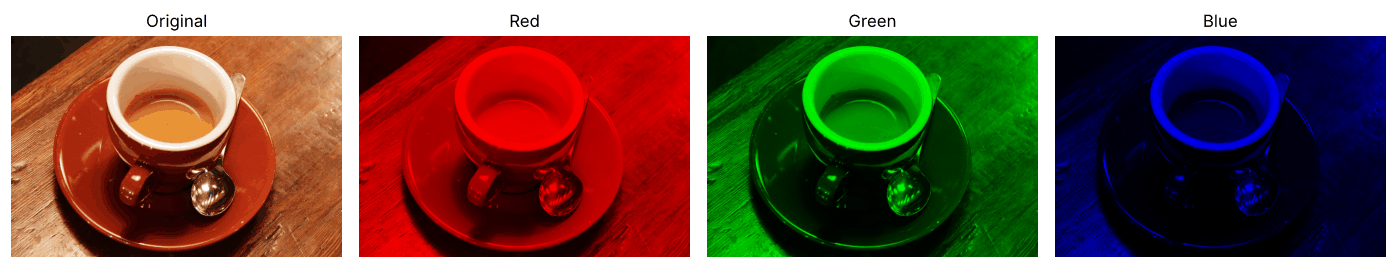

In [3]:
rgb = data.coffee()               # uint8, H×W×3
R, G, B = (rgb[..., i] for i in range(3))

tint = lambda ch, i: np.stack([ch if k == i else np.zeros_like(ch) for k in range(3)], -1)
show([rgb, tint(R, 0), tint(G, 1), tint(B, 2)], ["Original", "Red", "Green", "Blue"], save="color_rgb_channels.png")

## RGB → HSV, vectorised

With $C_{max}=\max(R,G,B)$, $C_{min}=\min(R,G,B)$ and $\Delta=C_{max}-C_{min}$:

$$V=C_{max},\qquad S=\begin{cases}0 & C_{max}=0\\ \Delta/C_{max} & \text{otherwise}\end{cases}$$

$$H=60^\circ\times\begin{cases}\frac{G-B}{\Delta}\bmod 6 & C_{max}=R\\ \frac{B-R}{\Delta}+2 & C_{max}=G\\ \frac{R-G}{\Delta}+4 & C_{max}=B\end{cases}$$

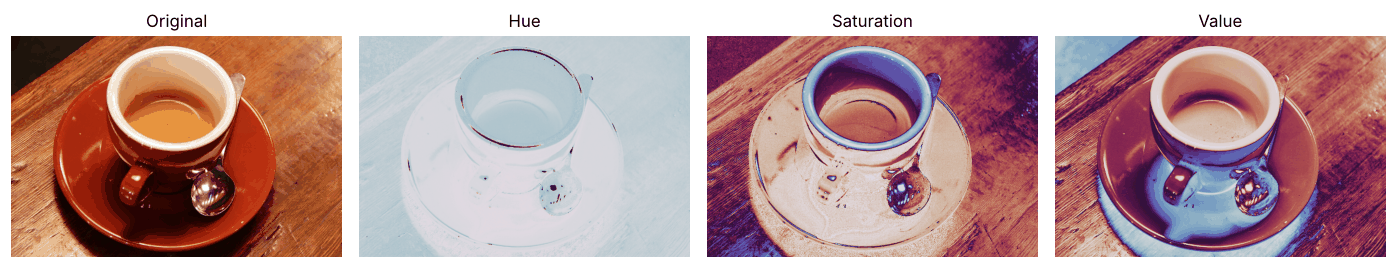

In [4]:
def rgb_to_hsv(img):
    """RGB uint8 -> HSV floats (H in degrees [0,360), S,V in [0,1])."""
    x = img.astype(np.float64) / 255.0
    r, g, b = x[..., 0], x[..., 1], x[..., 2]
    cmax, cmin = x.max(-1), x.min(-1)
    delta = cmax - cmin
    safe = np.where(delta == 0, 1, delta)

    h = np.zeros_like(cmax)
    h = np.where(cmax == r, ((g - b) / safe) % 6, h)
    h = np.where(cmax == g, (b - r) / safe + 2, h)
    h = np.where(cmax == b, (r - g) / safe + 4, h)
    h = np.where(delta == 0, 0, h) * 60.0

    s = np.where(cmax == 0, 0, delta / np.where(cmax == 0, 1, cmax))
    return np.stack([h, s, cmax], -1)

hsv = rgb_to_hsv(rgb)
show([rgb, hsv[..., 0], hsv[..., 1], hsv[..., 2]], ["Original", "Hue", "Saturation", "Value"],
     save="color_hsv.png", cmap="twilight")

### Sanity check against OpenCV

In [5]:
import cv2
ref = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV_FULL).astype(float)   # H in [0,255]
ours = np.stack([hsv[..., 0] / 360 * 256, hsv[..., 1] * 255, hsv[..., 2] * 255], -1)
diff = np.abs(ours - ref); diff[..., 0] = np.minimum(diff[..., 0], 256 - diff[..., 0])  # hue wraps
print(f"max |Δ| per channel (0-255 scale): H={diff[...,0].max():.2f}  S={diff[...,1].max():.2f}  V={diff[...,2].max():.2f}")

max |Δ| per channel (0-255 scale): H=0.50  S=0.52  V=0.00


## Bonus: hue-based color selection
HSV makes 'pick everything red-ish' a one-liner — something that's awkward in RGB.

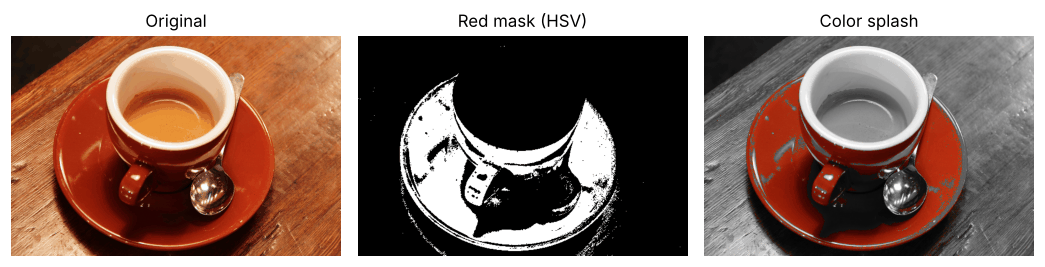

In [6]:
mask = ((hsv[..., 0] < 12) | (hsv[..., 0] > 345)) & (hsv[..., 1] > 0.65) & (hsv[..., 2] > 0.2)
gray = np.repeat(rgb.mean(-1, keepdims=True), 3, -1).astype(np.uint8)
splash = np.where(mask[..., None], rgb, gray)
show([rgb, mask.astype(float), splash], ["Original", "Red mask (HSV)", "Color splash"], save="color_splash.png")